# Step 1 — The same agent, at 10 and 15 players

Deliverable 03 trained this agent at 2, 3, 5 and 7 players and could mark its homework
every time, because folder 02 computes the exact answer at those counts. This step takes
the identical agent to **10 and 15 players**, where no exact answer is on record.

Two questions, and they are different:

1. **Does the code need changing?** Answered by doing it. One line comes out.
2. **Does the result mean anything without an answer key?** That is the harder one, and
   this step answers only the first half of it — by measuring the same quantity at five
   player counts in one script, so the trend is a single experiment rather than five
   results stitched together.

**What is new here.** 10 and 15 are the new training. 3, 5 and 7 are re-measured at the
same budget so the trend is internally consistent, and they double as a check against
step 9 of deliverable 03, which measured them in a different folder with its own copy of
the environment.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from gruel_env import GruelEnv, N_ACTIONS, MISS, SHOOT_LEFT, SHOOT_RIGHT

torch.set_num_threads(1)
print("torch", torch.__version__)

torch 2.2.2


## Settings

`ranked` seating, because the exact answers assume accuracies seated in ascending order,
and three of these five counts have an exact answer to be read against. Step 7 of
deliverable 03 showed that `random` seating gives a **different quantity** rather than a
noisier version of the same one, so it would not be comparable with those answers.

`terminal` reward, because it is the only profile an exact answer can grade.

In [2]:
PLAYER_COUNTS = [3, 5, 7, 10, 15]
REWARD = "terminal"
SEATING = "ranked"

OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64

UPDATES = 2000
EPISODES_PER_UPDATE = 96
EVALUATION_EPISODES = 10000
REFERENCE_EPISODES = 10000
SEEDS = [0, 1, 2]

LEARNING_RATE = 0.003
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01

GATE_THRESHOLD = 0.95
CLOSE = 0.01

print("player counts:", PLAYER_COUNTS)
print("reward:", REWARD, " seating:", SEATING)
print("budget per seed:", UPDATES, "updates x", EPISODES_PER_UPDATE, "episodes =",
      UPDATES * EPISODES_PER_UPDATE, "training episodes")
print("seeds:", SEEDS)

player counts: [3, 5, 7, 10, 15]
reward: terminal  seating: ranked
budget per seed: 2000 updates x 96 episodes = 192000 training episodes
seeds: [0, 1, 2]


## The answer key, and where it stops

Two separate facts, kept separate on purpose. One is about the **game**: an exact answer
is on record for 3 to 8 players, and folder 02 shows the solver being *refused* at 9 because no
pure equilibrium exists there — the limit is the method, not computing time. The other is
about **this folder**: which profiles it carries typed into its own source, since no folder
imports folder 02.

At 10 and 15 players both facts say the same thing, and that is the premise of the step.

In [3]:
EXACT_BY_RANK = {
    3: [0.37037, 0.33333, 0.29630],
    5: [0.24959, 0.21073, 0.17970, 0.16194, 0.19804],
    7: [0.15335, 0.17343, 0.14916, 0.13761, 0.12996, 0.13217, 0.12432],
}

EXACT_ANSWERS_EXIST_FOR = {3, 4, 5, 6, 7, 8}

EXACT_PROFILES_CARRIED = set(EXACT_BY_RANK)

for n in PLAYER_COUNTS:
    exists = n in EXACT_ANSWERS_EXIST_FOR
    carried = n in EXACT_PROFILES_CARRIED
    if carried:
        verdict = "graded against it"
    elif exists:
        verdict = "exists, but this folder does not carry it"
    else:
        verdict = "NO ANSWER -- described only"
    print("  N=%-3d exact answer exists: %-5s carried here: %-5s -> %s"
          % (n, exists, carried, verdict))

  N=3   exact answer exists: True  carried here: True  -> graded against it
  N=5   exact answer exists: True  carried here: True  -> graded against it
  N=7   exact answer exists: True  carried here: True  -> graded against it
  N=10  exact answer exists: False carried here: False -> NO ANSWER -- described only
  N=15  exact answer exists: False carried here: False -> NO ANSWER -- described only


## What changes when only the player count changes

The honest answer is: more than one thing, and the step says so rather than pretending the
count is a clean dial. Printed rather than asserted.

The accuracy **range is pinned to 0.4-0.8 whatever the count**, so the players are spread
more thinly as the field grows. A fifteen-player game is not a three-player game with
twelve more players in it; it is a game in which everyone is nearly equally skilled. That
matters for reading the trend and `## Reading the trend` below returns to it.

In [4]:
print("  N    accuracies            gap      decisions/episode   critic input   stagnation   hard cap")
for n in PLAYER_COUNTS:
    probe_game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=0)
    probe_game.reset()
    accuracies = [float(a) for a in probe_game.accuracies]
    gap = accuracies[1] - accuracies[0]

    # Measure the episode length rather than reasoning about it.
    lengths = []
    for _ in range(200):
        probe_game.reset()
        steps = 0
        for acting_agent in probe_game.agent_iter():
            observation, reward, termination, truncation, info = probe_game.last()
            if termination or truncation:
                probe_game.step(None)
                continue
            left, right = probe_game.neighbours(probe_game.position_of_agent[acting_agent])
            if probe_game.accuracies[left] > probe_game.accuracies[right]:
                probe_game.step(SHOOT_LEFT)
            else:
                probe_game.step(SHOOT_RIGHT)
            steps = steps + 1
        lengths.append(steps)

    print("  %-4d %.4f .. %.4f   %.4f   %17.1f   %12d   %10d   %8d"
          % (n, accuracies[0], accuracies[-1], gap, float(np.mean(lengths)),
             3 * n, 10 * n, 200 * n))

  N    accuracies            gap      decisions/episode   critic input   stagnation   hard cap
  3    0.4000 .. 0.8000   0.2000                 3.7              9           30        600
  5    0.4000 .. 0.8000   0.1000                 7.4             15           50       1000
  7    0.4000 .. 0.8000   0.0667                11.1             21           70       1400
  10   0.4000 .. 0.8000   0.0444                16.7             30          100       2000
  15   0.4000 .. 0.8000   0.0286                25.8             45          150       3000


## What does not change

The action space is three choices at every count, because on a circle you always have
exactly two neighbours. The observation is four numbers at every count. The actor network
is therefore the same shape at every count, and only the critic grows — which is the
centralised-training half of the architecture, and it is discarded after training.

In [5]:
print("  action space:      Discrete(%d) at every player count" % N_ACTIONS)
print("  observation size:  %d numbers at every player count" % OBSERVATION_SIZE)
print()

  action space:      Discrete(3) at every player count
  observation size:  4 numbers at every player count



## The agent and the measurement machinery, copied forward

Every definition below is step 9 of deliverable 03's, unchanged. Rule 1 says a step
copies the previous step forward rather than importing it, so this folder carries its
own copy and can be handed over on its own.

`collect_batch` reads each player's return from the environment rather than assuming
`1.0 for the winner, 0.0 for everyone else`. Under `terminal` the two are identical, so
nothing here depends on it; it matters the moment a shaped reward is used.

In [6]:
class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)
        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)


def global_state(game):
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)


def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector


def collect_batch(model, game, episodes):
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}
    agent_flags = {p: [] for p in range(game.n)}

    for _ in range(episodes):
        game.reset()
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}
        # What each player had already banked when it made each decision. Needed because
        # the return for a decision is whatever arrives AFTER it, and under `shaped`
        # rewards arrive throughout the episode rather than only at the end.
        episode_banked_before = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            banked_so_far = float(game.episode_returns[acting_agent])
            observation_tensor = torch.from_numpy(observation)
            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(torch.from_numpy(state_array),
                                    torch.from_numpy(agent_array))

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)
            episode_banked_before[actor].append(banked_so_far)

            game.step(int(action))

        for position in range(game.n):
            # The return for a decision is the reward-to-go: everything this player ended
            # the episode with, minus what it had already banked when it decided. With a
            # discount of 1 that is exactly the undiscounted sum of what came after.
            #
            # Reading it from the environment is the whole point of this step. Assuming
            # `1.0 for the winner, 0.0 for everyone else` is correct under `terminal` and
            # silently WRONG under `shaped`, where it would discard every kill bonus,
            # every elimination penalty and every survival tick -- and both arms would then
            # train on identical numbers and look identical for a reason that is a bug.
            name = game.agent_of_position[position]
            final_total = float(game.episode_returns[name])
            for index in range(len(episode_actions[position])):
                own_return = final_total - episode_banked_before[position][index]
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
    }
    return batch


def ppo_update(model, optimiser, batch, update_rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        update_rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            ratio = torch.exp(new_log_probabilities
                              - batch["old_log_probabilities"][index])
            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()


def make_agent_policy(model):
    def agent_policy(game, actor):
        name = game.agent_of_position[actor]
        observation = game.observe(name)
        with torch.no_grad():
            logits = model.action_logits(torch.from_numpy(observation))
        distribution = torch.distributions.Categorical(logits=logits)
        return int(distribution.sample())
    return agent_policy


def play_episodes(game, policy, episodes):
    records = []
    for _ in range(episodes):
        game.reset()
        decisions = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            action = policy(game, actor)

            # Recorded BEFORE stepping, because a kill contracts the circle.
            left, right = game.neighbours(actor)
            decisions.append({
                "accuracy": round(float(game.accuracies[actor]), 4),
                "action": action,
                "left_accuracy": round(float(game.accuracies[left]), 4),
                "right_accuracy": round(float(game.accuracies[right]), 4),
                "n_alive": game.n_alive(),
            })

            game.step(action)

        if len(game.order) == 1:
            survivor_accuracy = round(float(game.accuracies[game.order[0]]), 4)
        else:
            survivor_accuracy = None

        records.append({
            "survivor_accuracy": survivor_accuracy,
            "stagnated": game.reason == "stagnation",
            "hit_cap": game.reason == "hard_cap",
            "decisions": decisions,
        })
    return records


def stagnation_rate(records):
    stagnated = 0
    for record in records:
        if record["stagnated"]:
            stagnated = stagnated + 1
    return stagnated / len(records)


def cap_rate(records):
    hit = 0
    for record in records:
        if record["hit_cap"]:
            hit = hit + 1
    return hit / len(records)


def survival_by_accuracy(records, accuracies):
    wins = {}
    for accuracy in accuracies:
        wins[accuracy] = 0
    for record in records:
        if record["survivor_accuracy"] is not None:
            wins[record["survivor_accuracy"]] = wins[record["survivor_accuracy"]] + 1
    rates = {}
    for accuracy in sorted(wins):
        rates[accuracy] = wins[accuracy] / len(records)
    return rates


def eligible(decision):
    if decision["action"] == MISS:
        return False        # never fired, so it selected no target
    if decision["n_alive"] <= 2:
        return False        # left and right are the same player
    if decision["left_accuracy"] == decision["right_accuracy"]:
        return False        # neither neighbour is the stronger one
    return True


def chose_stronger(decision):
    if decision["action"] == SHOOT_LEFT:
        chosen = decision["left_accuracy"]
        other = decision["right_accuracy"]
    else:
        chosen = decision["right_accuracy"]
        other = decision["left_accuracy"]
    return chosen > other


def targeting_rate(records, accuracy=None):
    stronger = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            if accuracy is not None and decision["accuracy"] != accuracy:
                continue
            if not eligible(decision):
                continue
            decisions = decisions + 1
            if chose_stronger(decision):
                stronger = stronger + 1
    if decisions == 0:
        return None, 0, 0
    return stronger / decisions, stronger, decisions


def standard_error(probability, episodes):
    return (probability * (1 - probability) / episodes) ** 0.5


def ratio_gate(measured, exact, threshold=GATE_THRESHOLD):
    rows = []
    passed = True
    for accuracy in sorted(exact):
        ratio = measured[accuracy] / exact[accuracy]
        reaches = ratio >= threshold
        if not reaches:
            passed = False
        rows.append((accuracy, measured[accuracy], exact[accuracy], ratio, reaches))
    return rows, passed


def worst_ratio_of(measured, exact):
    lowest = None
    for accuracy in exact:
        ratio = measured[accuracy] / exact[accuracy]
        if lowest is None or ratio < lowest:
            lowest = ratio
    return lowest


class WrongVariant(Exception):
    """Raised when a comparison is asked for that the numbers cannot support."""


def shoot_strongest(game, actor):
    left, right = game.neighbours(actor)
    if game.accuracies[left] >= game.accuracies[right]:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def coin_flip(game, actor):
    if reference_rng.random() < 0.5:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def accuracies_of(n):
    game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=0)
    game.reset(seed=0)
    return [round(float(a), 4) for a in game.accuracies]

In [7]:
reference_rng = np.random.default_rng(0)

print("  N    actor in -> out   actor params   critic input   critic params")
for n in PLAYER_COUNTS:
    probe_model = SharedActorCritic(n_players=n)
    actor_params = 0
    critic_params = 0
    for parameter_name, parameter in probe_model.named_parameters():
        if parameter_name.startswith("actor"):
            actor_params = actor_params + parameter.numel()
        else:
            critic_params = critic_params + parameter.numel()
    print("  %-4d %d -> %d            %-14d %-14d %d"
          % (n, probe_model.actor_first.in_features, probe_model.actor_second.out_features,
             actor_params, probe_model.critic_first.in_features, critic_params))

print()
print("  the actor is the same size at every player count; only the critic grows,")
print("  and the critic is discarded after training")

  N    actor in -> out   actor params   critic input   critic params
  3    4 -> 3            515            9              705
  5    4 -> 3            515            15             1089
  7    4 -> 3            515            21             1473
  10   4 -> 3            515            30             2049
  15   4 -> 3            515            45             3009

  the actor is the same size at every player count; only the critic grows,
  and the critic is discarded after training


## The guard

`compare_to_exact` refuses unless three things hold: ranked seating, terminal reward, and
an exact profile carried for that player count. Steps 7, 8 and 9 of deliverable 03 each
built one of those conditions. Here the third does the work, because **10 and 15 cannot be
graded at all**, and this step has to show that rather than quietly skip it.

It is asked below on real measurements, after training, so the refusals are refusals of a
real request.

In [8]:
def exact_table(n):
    ranked = sorted(accuracies_of(n))
    if len(ranked) != len(EXACT_BY_RANK[n]):
        raise ValueError("exact list length does not match the player count")
    table = {}
    for rank in range(len(ranked)):
        table[ranked[rank]] = EXACT_BY_RANK[n][rank]
    return table


def compare_to_exact(measured, n, seating=SEATING, reward=REWARD):
    """Refuse the comparison unless all three preconditions hold."""
    if seating != "ranked":
        raise WrongVariant(
            "the exact profile assumes accuracies seated in ascending order; "
            "random seating re-deals every episode, so the measurement averages "
            "over every arrangement and is a different quantity")
    if reward != "terminal":
        raise WrongVariant(
            "the exact profile is a set of survival probabilities; a shaped reward "
            "maximises something else, so the comparison would grade the agent on an "
            "objective it was never given")
    if n not in EXACT_PROFILES_CARRIED:
        if n in EXACT_ANSWERS_EXIST_FOR:
            raise WrongVariant(
                "an exact answer exists at N=%d but this folder does not carry it; "
                "folder 02-exact-solver derives it" % n)
        raise WrongVariant(
            "no exact answer is on record at N=%d, so there is nothing to compare "
            "against; above the recorded range the method changes from validating to "
            "characterising" % n)
    return ratio_gate(measured, exact_table(n))

## Training

One model per player count per seed. Nothing in `train_one` knows which count it is
training at — the count arrives as an argument and the network sizes itself from it.

In [9]:
def train_one(n, seed):
    torch.manual_seed(2000 + seed)
    game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=1000 + seed)
    model = SharedActorCritic(n_players=n)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    update_rng = np.random.default_rng(seed)

    for update in range(UPDATES):
        batch = collect_batch(model, game, EPISODES_PER_UPDATE)
        ppo_update(model, optimiser, batch, update_rng)
    return model


def measure(model, n, seed):
    game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=5000 + seed)
    torch.manual_seed(7000 + seed)
    return play_episodes(game, make_agent_policy(model), EVALUATION_EPISODES)

## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [10]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step1_train_any_n.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [11]:
import time

TRAINED = {}
RECORDS = {}
ACCURACIES = {}

overall_started = time.time()
for n in PLAYER_COUNTS:
    ACCURACIES[n] = accuracies_of(n)
    TRAINED[n] = {}
    RECORDS[n] = {}
    for seed in SEEDS:
        started = time.time()
        TRAINED[n][seed] = train_one(n, seed)
        save_model(TRAINED[n][seed], run_key(n, SEATING, REWARD, "centralised", UPDATES, seed),
                   mappo_settings(n, REWARD, SEATING, seed, UPDATES, EPISODES_PER_UPDATE,
                                  "centralised", time.time() - started, "training only"))
        RECORDS[n][seed] = measure(TRAINED[n][seed], n, seed)
        print("  N=%-3d seed %d  trained and measured in %5.1f min"
              % (n, seed, (time.time() - started) / 60.0), flush=True)
print("  total %.1f min" % ((time.time() - overall_started) / 60.0))

  N=3   seed 0  trained and measured in   1.1 min


  N=3   seed 1  trained and measured in   1.3 min


  N=3   seed 2  trained and measured in   1.5 min


  N=5   seed 0  trained and measured in   2.8 min


  N=5   seed 1  trained and measured in   2.9 min


  N=5   seed 2  trained and measured in   3.0 min


... (6 outputs left out)

  N=15  seed 0  trained and measured in   9.4 min


  N=15  seed 1  trained and measured in   9.7 min


  N=15  seed 2  trained and measured in   9.5 min


  total 70.8 min


## The survival profile at each player count

Weakest rank first. Under `terminal` a player's survival probability **is** its expected
return, so these are exactly the quantity the exact solver computes — where it can.

Per-seed numbers are shown alongside the pooled ones, because with no answer key the spread
across seeds is most of what tells you whether a number means anything. Two standard errors
are printed: `eval SE` is the binomial noise of 30,000 evaluation episodes, and `seed SE` is
the standard deviation across the three seeds divided by $\sqrt{3}$. Where they differ, the
seed SE is the honest error bar on the pooled number.

In [12]:
PER_SEED = {}
POOLED = {}

for n in PLAYER_COUNTS:
    accuracies = ACCURACIES[n]
    PER_SEED[n] = {}
    for seed in SEEDS:
        rates = survival_by_accuracy(RECORDS[n][seed], accuracies)
        PER_SEED[n][seed] = [rates[a] for a in sorted(rates)]

    pooled = []
    for index in range(n):
        values = [PER_SEED[n][seed][index] for seed in SEEDS]
        pooled.append(float(np.mean(values)))
    POOLED[n] = pooled

    episodes = EVALUATION_EPISODES * len(SEEDS)
    print("  N=%d  pooled over %d seeds, %d episodes each:" % (n, len(SEEDS), EVALUATION_EPISODES))
    print("     measured  " + "  ".join(format(p, ".4f") for p in pooled))
    # Two different errors. The first is the evaluation's binomial noise for a fixed set of
    # trained models; the second is how much the answer moves between training seeds, which
    # is the one that matters when asking what the method produces.
    print("     eval SE   " + "  ".join(format(standard_error(p, episodes), ".4f") for p in pooled))
    seed_errors = []
    for index in range(n):
        values = [PER_SEED[n][seed][index] for seed in SEEDS]
        seed_errors.append(float(np.std(values, ddof=1)) / len(SEEDS) ** 0.5)
    print("     seed SE   " + "  ".join(format(e, ".4f") for e in seed_errors))
    for seed in SEEDS:
        print("     seed %d    " % seed
              + "  ".join(format(p, ".4f") for p in PER_SEED[n][seed]))
    print("     sums to %.4f" % sum(pooled))
    print()

  N=3  pooled over 3 seeds, 10000 episodes each:
     measured  0.3700  0.3335  0.2965
     eval SE   0.0028  0.0027  0.0026
     seed SE   0.0013  0.0016  0.0012
     seed 0    0.3694  0.3316  0.2990
     seed 1    0.3680  0.3367  0.2953
     seed 2    0.3725  0.3322  0.2953
     sums to 1.0000

  N=5  pooled over 3 seeds, 10000 episodes each:
     measured  0.2490  0.2129  0.1857  0.1578  0.1947
     eval SE   0.0025  0.0024  0.0022  0.0021  0.0023
     seed SE   0.0070  0.0015  0.0031  0.0034  0.0027
     seed 0    0.2411  0.2111  0.1862  0.1621  0.1995
     seed 1    0.2429  0.2159  0.1908  0.1602  0.1902
     seed 2    0.2629  0.2117  0.1800  0.1510  0.1944
     sums to 1.0000

  N=7  pooled over 3 seeds, 10000 episodes each:
     measured  0.1706  0.1459  0.1308  0.1218  0.1176  0.1230  0.1903
     eval SE   0.0022  0.0020  0.0019  0.0019  0.0019  0.0019  0.0023
     seed SE   0.0191  0.0133  0.0081  0.0025  0.0036  0.0092  0.0324
     seed 0    0.1326  0.1212  0.1153  0.1168  0.

## Asking for the comparison, on every player count

The same request, five times. Three are answered and two are refused, and the refusal text
is the step's main claim: above the recorded range the method changes from validating to
characterising.

In [13]:
WORST_RATIO = {}

for n in PLAYER_COUNTS:
    measured = {}
    ranked = sorted(ACCURACIES[n])
    for index in range(n):
        measured[ranked[index]] = POOLED[n][index]
    try:
        rows, passed = compare_to_exact(measured, n)
        ratios = [row[3] for row in rows]
        WORST_RATIO[n] = min(ratios)
        print("  N=%d  COMPARISON ANSWERED" % n)
        print("     measured  " + "  ".join(format(row[1], ".4f") for row in rows))
        print("     exact     " + "  ".join(format(row[2], ".5f") for row in rows))
        print("     ratio     " + "  ".join(format(row[3], ".3f") for row in rows))
        print("     worst ratio %.3f, reaches %.2f: %s"
              % (min(ratios), GATE_THRESHOLD, passed))
    except WrongVariant as refusal:
        WORST_RATIO[n] = None
        print("  N=%d  REFUSED" % n)
        print("     %s" % refusal)
    print()

  N=3  COMPARISON ANSWERED
     measured  0.3700  0.3335  0.2965
     exact     0.37037  0.33333  0.29630
     ratio     0.999  1.001  1.001
     worst ratio 0.999, reaches 0.95: True

  N=5  COMPARISON ANSWERED
     measured  0.2490  0.2129  0.1857  0.1578  0.1947
     exact     0.24959  0.21073  0.17970  0.16194  0.19804
     ratio     0.998  1.010  1.033  0.974  0.983
     worst ratio 0.974, reaches 0.95: True

  N=7  COMPARISON ANSWERED
     measured  0.1706  0.1459  0.1308  0.1218  0.1176  0.1230  0.1903
     exact     0.15335  0.17343  0.14916  0.13761  0.12996  0.13217  0.12432
     ratio     1.112  0.841  0.877  0.885  0.905  0.930  1.531
     worst ratio 0.841, reaches 0.95: False

  N=10  REFUSED
     no exact answer is on record at N=10, so there is nothing to compare against; above the recorded range the method changes from validating to characterising

  N=15  REFUSED
     no exact answer is on record at N=15, so there is nothing to compare against; above the recorded rang

The other two conditions still hold here, and are asked on the same real measurement so
the refusals are not hypothetical.

In [14]:
five = 5
measured_five = {}
ranked_five = sorted(ACCURACIES[five])
for index in range(five):
    measured_five[ranked_five[index]] = POOLED[five][index]

for case in [{"seating": "random", "reward": "terminal"},
             {"seating": "ranked", "reward": "shaped"}]:
    try:
        compare_to_exact(measured_five, five,
                         seating=case["seating"], reward=case["reward"])
        print("  N=5 %s %s: answered" % (case["seating"], case["reward"]))
    except WrongVariant as refusal:
        print("  N=5 %s/%s REFUSED: %s" % (case["seating"], case["reward"], refusal))

  N=5 random/terminal REFUSED: the exact profile assumes accuracies seated in ascending order; random seating re-deals every episode, so the measurement averages over every arrangement and is a different quantity
  N=5 ranked/shaped REFUSED: the exact profile is a set of survival probabilities; a shaped reward maximises something else, so the comparison would grade the agent on an objective it was never given


## Reading the trend

The weakest player's survival as a multiple of an even $1/N$ share. This is the brief's
first phenomenon, survival of the weakest, asked across five player counts.

The exact answer is shown where one exists. Note what the exact answer does: it **peaks and
then reverses**, so a measured ratio that keeps climbing is not evidence of good play.

In [15]:
EXACT_RATIO = {3: 1.111, 5: 1.248, 7: 1.073}

agent_ratios = []
print("  N    agent weakest/uniform   per seed                        exact")
for n in PLAYER_COUNTS:
    per_seed = [PER_SEED[n][seed][0] * n for seed in SEEDS]
    pooled_ratio = POOLED[n][0] * n
    agent_ratios.append(pooled_ratio)
    if n in EXACT_RATIO:
        exact_shown = "%.3f" % EXACT_RATIO[n]
    else:
        exact_shown = "none on record"
    print("  %-4d %18.3f      %s      %s"
          % (n, pooled_ratio, "  ".join(format(r, ".3f") for r in per_seed), exact_shown))

if len(SEEDS) < 2:
    print()
    print("  cannot judge a direction from %d seed(s) -- no error bar" % len(SEEDS))

  N    agent weakest/uniform   per seed                        exact
  3                 1.110      1.108  1.104  1.117      1.111
  5                 1.245      1.206  1.215  1.315      1.248
  7                 1.194      0.928  1.296  1.357      1.073
  10                1.503      1.555  1.445  1.510      none on record
  15                1.517      1.173  1.731  1.646      none on record


### Two things vary together along this axis

Growing the player count also **tightens the accuracy spread**, because the range stays
pinned to 0.4-0.8. So "as N grows" means two things at once in this design, and this design
cannot separate them. `GAME.md` states the arithmetic.

The direction is worth naming because it is not the intuitive one. Folder 02's step 4 settles
it with the solver, two ways. At a fixed player count, a tighter field generally **raises**
the weakest player's advantage. With the spacing frozen, the advantage still falls as players
are added. So the tightening that comes with a larger field works against any fall in this
trend rather than causing it.

This folder does not repeat that test. It is noted so the trend is not over-read.

## Abstention — the brief's second phenomenon

The classical result says the weakest player in a *fixed-order* truel should deliberately
miss. This is the random-order variant, in which both shooting and non-shooting equilibria
exist, so the real question is which one the agents select.

Classified before any survival number is read, because a run that stagnates is answering a
different question.

In [16]:
print("  N    abstention   per seed                        stagnation   hard cap")
abstention_pooled = {}
for n in PLAYER_COUNTS:
    per_seed = []
    for seed in SEEDS:
        misses = 0
        decisions = 0
        for record in RECORDS[n][seed]:
            for decision in record["decisions"]:
                decisions = decisions + 1
                if decision["action"] == MISS:
                    misses = misses + 1
        if decisions == 0:
            per_seed.append(None)
        else:
            per_seed.append(misses / decisions)

    usable = [r for r in per_seed if r is not None]
    if len(usable) == 0:
        print("  %-4d no decisions recorded -- nothing to report" % n)
        continue
    abstention_pooled[n] = float(np.mean(usable))

    all_records = []
    for seed in SEEDS:
        all_records.extend(RECORDS[n][seed])
    print("  %-4d %10.4f   %s      %10.4f   %8.4f"
          % (n, abstention_pooled[n],
             "  ".join(format(r, ".4f") for r in usable),
             stagnation_rate(all_records), cap_rate(all_records)))

print()
highest = max(abstention_pooled, key=lambda k: abstention_pooled[k])
print("  highest abstention at N=%d: %.4f" % (highest, abstention_pooled[highest]))
if abstention_pooled[highest] < 0.01:
    print("  -> below 1% everywhere: the agents select the shooting equilibrium at every count")
else:
    print("  -> above 1% somewhere, so abstention is NOT negligible at every count here")
    print("     and the figure belongs in the write-up rather than being waved away")

  N    abstention   per seed                        stagnation   hard cap
  3        0.0002   0.0003  0.0000  0.0002          0.0000     0.0000
  5        0.0001   0.0001  0.0003  0.0000          0.0000     0.0000
  7        0.0001   0.0000  0.0002  0.0000          0.0000     0.0000
  10       0.0003   0.0007  0.0001  0.0000          0.0000     0.0000


  15       0.0992   0.0000  0.2976  0.0001          0.0000     0.0000

  highest abstention at N=15: 0.0992
  -> above 1% somewhere, so abstention is NOT negligible at every count here
     and the figure belongs in the write-up rather than being waved away


### When and who: breaking a high abstention rate down

A pooled rate cannot say whether missing is spread evenly through a game or concentrated in one
part of it, nor whether one kind of player does it. So every run whose abstention rate is above
1% is broken down three ways: by how many players are still in the game, by the player's own
strength, and by its strength relative to the two neighbours it can shoot.

Runs below 1% are not broken down, because a handful of misses split many ways says nothing.

In [17]:
BREAKDOWN_THRESHOLD = 0.01


def miss_rate(decision_list):
    """Share of these decisions that were deliberate misses, or None if there were none."""
    missed = 0
    for decision in decision_list:
        if decision["action"] == MISS:
            missed = missed + 1
    if len(decision_list) == 0:
        return None, 0, 0
    return missed / len(decision_list), missed, len(decision_list)


def where_it_stands(decision):
    """The player's strength relative to its two neighbours."""
    own = decision["accuracy"]
    left_side = decision["left_accuracy"]
    right_side = decision["right_accuracy"]
    if left_side == right_side:
        return "neighbours are the same player (2 alive)"
    if own < min(left_side, right_side):
        return "weaker than both neighbours"
    if own > max(left_side, right_side):
        return "stronger than both neighbours"
    return "between its two neighbours"


runs_broken_down = 0
for n in PLAYER_COUNTS:
    for seed in SEEDS:
        run_decisions = []
        for record in RECORDS[n][seed]:
            for decision in record["decisions"]:
                run_decisions.append(decision)
        overall, overall_missed, overall_count = miss_rate(run_decisions)
        if overall is None or overall <= BREAKDOWN_THRESHOLD:
            continue
        runs_broken_down = runs_broken_down + 1

        print("N=%d seed %d: %d of %d decisions were deliberate misses (%.4f)"
              % (n, seed, overall_missed, overall_count, overall))
        print()
        print("  by players still in the game")
        early_missed = 0
        for alive_count in range(n, 1, -1):
            at_this_count = []
            for decision in run_decisions:
                if decision["n_alive"] == alive_count:
                    at_this_count.append(decision)
            rate, missed, count = miss_rate(at_this_count)
            if rate is not None:
                print("    %2d alive   %.4f   (%d of %d)" % (alive_count, rate, missed, count))
            if alive_count > (2 * n) / 3:
                early_missed = early_missed + missed
        print("  share of this run's misses made while more than two thirds of the field"
              " remained: %.3f" % (early_missed / overall_missed))
        print()
        print("  by the player's own strength (rank 0 = weakest)")
        ranked_accuracies = sorted(ACCURACIES[n])
        for rank in range(len(ranked_accuracies)):
            at_this_rank = []
            for decision in run_decisions:
                if decision["accuracy"] == ranked_accuracies[rank]:
                    at_this_rank.append(decision)
            rate, missed, count = miss_rate(at_this_rank)
            print("    rank %2d  accuracy %.4f   %.4f   (%d of %d)"
                  % (rank, ranked_accuracies[rank], rate, missed, count))
        print()
        print("  by strength relative to its two neighbours")
        for standing in ["weaker than both neighbours", "between its two neighbours",
                         "stronger than both neighbours",
                         "neighbours are the same player (2 alive)"]:
            in_this_standing = []
            for decision in run_decisions:
                if where_it_stands(decision) == standing:
                    in_this_standing.append(decision)
            rate, missed, count = miss_rate(in_this_standing)
            print("    %-42s %.4f   (%d of %d)" % (standing, rate, missed, count))
        print()

if runs_broken_down == 0:
    print("no run abstains in more than 1% of its decisions, so there is nothing to break down")

N=15 seed 1: 100625 of 338127 decisions were deliberate misses (0.2976)

  by players still in the game
    15 alive   0.7808   (54965 of 70395)
    14 alive   0.6256   (26065 of 41663)
    13 alive   0.4209   (11687 of 27766)


    12 alive   0.2356   (5036 of 21373)
    11 alive   0.1022   (1921 of 18805)
    10 alive   0.0374   (657 of 17577)
     9 alive   0.0127   (223 of 17492)
     8 alive   0.0032   (56 of 17301)
     7 alive   0.0007   (13 of 17344)
     6 alive   0.0001   (1 of 17325)
     5 alive   0.0001   (1 of 17418)


     4 alive   0.0000   (0 of 17470)
     3 alive   0.0000   (0 of 17766)
     2 alive   0.0000   (0 of 18432)
  share of this run's misses made while more than two thirds of the field remained: 0.991

  by the player's own strength (rank 0 = weakest)
    rank  0  accuracy 0.4000   0.2421   (7127 of 29444)
    rank  1  accuracy 0.4286   0.3399   (9670 of 28450)
    rank  2  accuracy 0.4571   0.3492   (9530 of 27289)


    rank  3  accuracy 0.4857   0.3445   (8818 of 25596)
    rank  4  accuracy 0.5143   0.3345   (8169 of 24424)
    rank  5  accuracy 0.5429   0.3427   (7816 of 22808)
    rank  6  accuracy 0.5714   0.3298   (7237 of 21943)
    rank  7  accuracy 0.6000   0.3211   (6730 of 20959)
    rank  8  accuracy 0.6286   0.3107   (6124 of 19712)


    rank  9  accuracy 0.6571   0.2809   (5427 of 19323)
    rank 10  accuracy 0.6857   0.2785   (5033 of 18074)
    rank 11  accuracy 0.7143   0.2553   (4367 of 17106)
    rank 12  accuracy 0.7429   0.2376   (4103 of 17271)
    rank 13  accuracy 0.7714   0.1842   (3718 of 20188)
    rank 14  accuracy 0.8000   0.2645   (6756 of 25540)

  by strength relative to its two neighbours


    weaker than both neighbours                0.1900   (7218 of 37999)


    between its two neighbours                 0.3545   (86401 of 243717)
    stronger than both neighbours              0.1845   (7006 of 37979)


    neighbours are the same player (2 alive)   0.0000   (0 of 18432)



## Heuristic references, measured in the same run

With no exact answer at 10 and 15, a measured number needs something to be read against.
Heuristics need no training, so they cost seconds and can be measured under exactly the
same conditions as the agent rather than quoted from elsewhere.

`shoot_strongest` is the one to watch. Its weakest-player advantage **climbs at every
player count**, which is that heuristic's signature rather than a sign of good play — and
it is the reason this project does not treat a large ratio as a result.

In [18]:
REFERENCE_RATIO = {}

print("  N    agent    shoot_strongest   coin_flip")
for n in PLAYER_COUNTS:
    row = {}
    for label, policy in [("shoot_strongest", shoot_strongest), ("coin_flip", coin_flip)]:
        game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=7000 + n)
        records = play_episodes(game, policy, REFERENCE_EPISODES)
        rates = survival_by_accuracy(records, ACCURACIES[n])
        weakest = sorted(rates)[0]
        row[label] = rates[weakest] * n
    REFERENCE_RATIO[n] = row
    print("  %-4d %7.3f  %15.3f   %9.3f"
          % (n, POOLED[n][0] * n, row["shoot_strongest"], row["coin_flip"]))

  N    agent    shoot_strongest   coin_flip


  3      1.110            1.118       0.647


  5      1.245            2.022       0.685


  7      1.194            2.983       0.666


  10     1.503            4.442       0.692


  15     1.517            6.769       0.710


### What the comparison does and does not say

Derived from the measurements above rather than asserted, because the direction is the
whole question and a hardcoded verdict would survive the numbers changing.

In [19]:
heuristic_ratios = [REFERENCE_RATIO[n]["shoot_strongest"] for n in PLAYER_COUNTS]

agent_rises_everywhere = True
heuristic_rises_everywhere = True
for index in range(1, len(PLAYER_COUNTS)):
    if agent_ratios[index] <= agent_ratios[index - 1]:
        agent_rises_everywhere = False
    if heuristic_ratios[index] <= heuristic_ratios[index - 1]:
        heuristic_rises_everywhere = False

print("  agent ratio rises at every step:           ", agent_rises_everywhere)
print("  shoot_strongest ratio rises at every step: ", heuristic_rises_everywhere)
print()
print("  agent,           N=3 -> N=15:  %.3f -> %.3f" % (agent_ratios[0], agent_ratios[-1]))
print("  shoot_strongest, N=3 -> N=15:  %.3f -> %.3f"
      % (heuristic_ratios[0], heuristic_ratios[-1]))
print()
largest = PLAYER_COUNTS[-1]
share = agent_ratios[-1] / heuristic_ratios[-1]
print("  at N=%d the agent sits at %.2f of shoot_strongest's advantage" % (largest, share))
if share < 0.5:
    print("  -> under half, so the agent is not reproducing that heuristic's signature")
else:
    print("  -> at or above half, so which policy was found cannot be settled from survival")
    print("     alone and needs the targeting measurement")
print()
print("  Either way, two policies can produce the same survival profile, so this comparison")
print("  ranks outcomes and does not identify behaviour. That is what targeting is for.")

  agent ratio rises at every step:            False
  shoot_strongest ratio rises at every step:  True

  agent,           N=3 -> N=15:  1.110 -> 1.517
  shoot_strongest, N=3 -> N=15:  1.118 -> 6.769

  at N=15 the agent sits at 0.22 of shoot_strongest's advantage
  -> under half, so the agent is not reproducing that heuristic's signature

  Either way, two policies can produce the same survival profile, so this comparison
  ranks outcomes and does not identify behaviour. That is what targeting is for.


## The picture

One line per source. The exact answer stops where it stops, and that gap is the subject of
this folder.

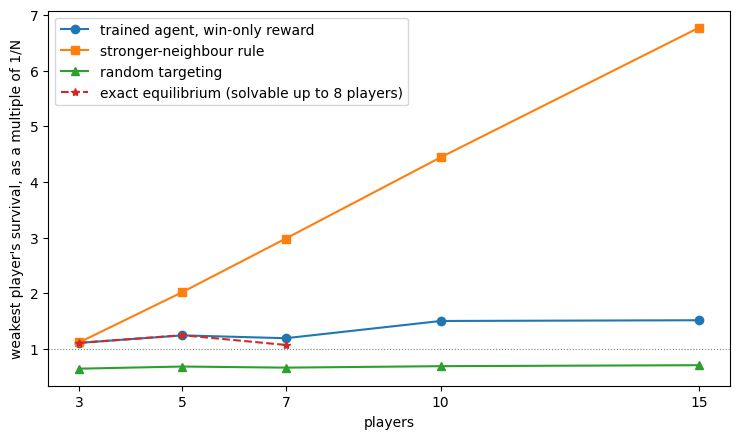

In [20]:
figure, axis = plt.subplots(figsize=(7.5, 4.5))
axis.plot(PLAYER_COUNTS, agent_ratios, marker="o", label="trained agent, win-only reward")
axis.plot(PLAYER_COUNTS, heuristic_ratios, marker="s", label="stronger-neighbour rule")
axis.plot(PLAYER_COUNTS,
          [REFERENCE_RATIO[n]["coin_flip"] for n in PLAYER_COUNTS],
          marker="^", label="random targeting")
exact_counts = []
for n in PLAYER_COUNTS:
    if n in EXACT_RATIO:
        exact_counts.append(n)
axis.plot(exact_counts, [EXACT_RATIO[n] for n in exact_counts],
          marker="*", linestyle="--", label="exact equilibrium (solvable up to 8 players)")
axis.axhline(1.0, color="grey", linewidth=0.8, linestyle=":")
axis.set_xlabel("players")
axis.set_ylabel("weakest player's survival, as a multiple of 1/N")
axis.set_xticks(PLAYER_COUNTS)
axis.legend()
figure.tight_layout()
plt.show()

## What this step hands to the next one

A survival profile at 10 and 15 players that **nothing can check against an exact answer**.
One test still works without one: folder 02 defines an equilibrium as a strategy no single
player can improve on by changing what it does alone, and that can be measured directly by
letting one seat switch to something else. That is the next step.

## Reproducibility

Two random streams have to be reset, not one. The environment has its own, and a trained
policy **samples**, which uses torch's global stream. Resetting only the environment leaves
the policy's stream wherever the previous call left it, and the check then fails for a
reason that has nothing to do with the result.

In [21]:
def measure_once():
    n = PLAYER_COUNTS[-1]
    torch.manual_seed(7000)
    game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=9000)
    records = play_episodes(game, make_agent_policy(TRAINED[n][SEEDS[0]]), 400)
    rates = survival_by_accuracy(records, ACCURACIES[n])
    return rates[sorted(rates)[0]]


first = measure_once()
second = measure_once()
print("  first  run:", format(first, ".6f"))
print("  second run:", format(second, ".6f"))
print("  identical:", first == second)

  first  run: 0.085000
  second run: 0.085000
  identical: True
